In [1]:
from graph import create_graph

In [21]:
from graph import create_graph

graph_v0 = create_graph()
graph_v1 = create_graph() 

 # ✅ Already compiled

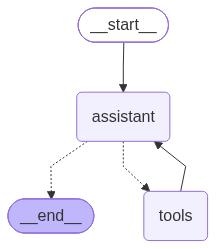

In [3]:
from IPython.display import Image, display
try:
    display(Image(graph_v0.get_graph().draw_mermaid_png()))
except Exception as ex:
    print("Couldnot render png")

Lets talk to the graph



.A customer with some concern

In [4]:
from langchain_core.messages import HumanMessage

turn_1 = graph_v0.invoke({
    "messages": [HumanMessage("I need a fix for skin detan")]
})

turn_1["messages"][-1].pretty_print()

================================== Ai Message ==================================

[{'type': 'text', 'text': 'To help you fix skin detan and brighten your skin tone, I would recommend our **Radiance C Vitamin Serum** (which helps improve dullness and even out skin tone) along with our **SunShield Daily Sunscreen SPF 50** to protect your skin from future sun exposure and tanning. \n\nTo help me tailor this recommendation for you, what is your skin type (for example, oily, dry, or sensitive)?', 'extras': {'signature': 'AY89a19ZlVKCoSe2dXy78B0WFQ0rAnDNgk60tcoAugG7UPRh3u/DYyhAYudHQ4JQxDaGVB6Ptn78A2tiD2NcnkZHgRLDr/hR3tkDbU4DhpXqJzYc9kVP94Ie/yM='}}]


Problem

.We are about to ask a follow up question

.The agent has no idea

In [5]:
turn_2 = graph_v0.invoke({
    "messages": [HumanMessage("Which product did you just recommend?")]
})
turn_2["messages"][-1].pretty_print()

================================== Ai Message ==================================

[{'type': 'text', 'text': "Hello! I haven't recommended any products to you yet. \n\nTo help me find the best product for you, could you please tell me what kind of personal care concern or goal you are looking to address today?", 'extras': {'signature': 'AY89a18jcLjbp67IW/qUabFs4WX5VrLU3e7HMDYajzLfWcnczgjxZSLO5H3hmhnKnckSaHbw6PnpdmEDRYKmWhLbepWt0JxSGTHN9n+RNIYtk6EOW348arkQSvE='}}]


In [6]:
print(f"Messages at the end of turn_1: ", len(turn_1["messages"]))
print(f"Messages at the end of turn_2: ", len(turn_2["messages"]))

Messages at the end of turn_1:  4
Messages at the end of turn_2:  2


In [7]:
from graph import create_graph
from langgraph.checkpoint.memory import InMemorySaver

# Create the checkpointer
checkpointer = InMemorySaver()

# Create the graph with memory enabled
graph_v1 = create_graph(checkpointer=checkpointer)

In [8]:
cfg = {"configurable": {"thread_id": "some-conversation-id"}}

In [9]:
turn_1 = graph_v1.invoke({
    "messages": [HumanMessage("I need a fix for skin detan")]
}, cfg)

turn_1["messages"][-1].pretty_print()

================================== Ai Message ==================================

[{'type': 'text', 'text': 'To help with dullness and uneven skin tone caused by sun exposure or tanning, I recommend our **Radiance C Vitamin Serum**. It is formulated with vitamin C to brighten the skin, improve radiance, and help even out your skin tone. \n\nTo help us get your order started, could you please share your full name?', 'extras': {'signature': 'AY89a18V06KxjsTGdY4+FGL9EIx+2PhkfvWiMld1sSxSBDgLYKUIGiSGcAHjqAKTASzIbZXQlo/KXoxv0nlMXwAP6fA3YzjlkMQ7vuv/oK8iPojMMtGSmCe3S2U='}}]


In [10]:
turn_2 = graph_v1.invoke({
    "messages": [HumanMessage("Which product did you just recommend?")]
}, cfg)
turn_2["messages"][-1].pretty_print()

================================== Ai Message ==================================

[{'type': 'text', 'text': 'I recommended the **Radiance C Vitamin Serum** (Product ID: `LREAL-SKIN-003`). It is priced at ₹699 for 30 ml and is designed to brighten dull-looking skin, improve radiance, and help even out skin tone affected by environmental stress and sun exposure.', 'extras': {'signature': 'AY89a18YjkvDuYquhpKbvMwlHY7/M04j01T6IflyFm2w5e+oLagvZvyWchoM+5IcWNlNOe3cPo9fD/RWNaOtZJ7DAN92JsfSXcadIk9uRybA1T1MObMV8V/eP8s='}}]


In [11]:

print(f"Messages at the end of turn_1: ", len(turn_1["messages"]))
print(f"Messages at the end of turn_2: ", len(turn_2["messages"]))

Messages at the end of turn_1:  4
Messages at the end of turn_2:  6


In [12]:
snapshot = graph_v1.get_state(cfg)
snapshot

StateSnapshot(values={'messages': [HumanMessage(content='I need a fix for skin detan', additional_kwargs={}, response_metadata={}, id='a6202020-5e47-44cf-ba8f-4fd867438eec'), AIMessage(content=[], additional_kwargs={'function_call': {'name': 'get_all_products', 'arguments': '{}'}, '__gemini_function_call_thought_signatures__': {'call_59902': 'AY89a19/Yk4cAeEBbFS/lGH9WO2tSrs2Vl0q74qkt2f8p8OOU9xyGO5hb6bkHeY34A74dfpnVDJ8nvT+65me1/ikkqDksHO1KBq8TSqyxsN1b0DXd8PUcw6mhEQ='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a12ebb-44a2-74b3-8c62-e991f08b7003-0', tool_calls=[{'name': 'get_all_products', 'args': {}, 'id': 'call_59902', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 502, 'output_tokens': 12, 'total_tokens': 514, 'input_token_details': {'cache_read': 0}}), ToolMessage(content="product_id | category | product_name | description | price_inr | size 

In [13]:
snapshot.config


{'configurable': {'thread_id': 'some-conversation-id',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1c6038-c1b0-60cc-8006-5a4ead216d81'}}

In [14]:
for m in snapshot.values["messages"]:
    label = type(m).__name__
    if isinstance(m.content, str) and m.content != "" :
        body = m.content.replace("\n", " ")
    print(f"{label}  {body}")

HumanMessage  I need a fix for skin detan
AIMessage  I need a fix for skin detan
ToolMessage  product_id | category | product_name | description | price_inr | size | how_to_use | benefits | problems_it_solves | suitable_for LREAL-SKIN-001 | skin_care | HydraGlow Gentle Face Cleanser | A gentle, hydrating facial cleanser designed to remove dirt, excess oil, and daily impurities without leaving the skin feeling dry. | 349 | 100 ml | Wet your face with lukewarm water.; Apply a small amount of cleanser.; Massage gently in circular motions for 30 to 60 seconds.; Rinse thoroughly and pat dry. | Cleanses the skin; Helps maintain skin hydration; Removes excess oil; Leaves skin feeling fresh | Daily facial dirt; Excess oil; Skin feeling tight after cleansing; Mild dryness caused by harsh cleansers | Normal skin; Dry skin; Combination skin LREAL-SKIN-002 | skin_care | ClearBalance Oil Control Serum | A lightweight facial serum formulated for oily and combination skin to help manage excess oil an

In [15]:
## Adding multiple customers

def chat(thread_id="new-session"):
    cfg = {"configurable": {"thread_id": thread_id}}
    print(f"Chatting on thread: {thread_id}")
    while True:
        text = input("You: ")
        if text.strip().lower() in {'exit', 'quit', ''}:
            print("\n ended")
            break
        out = graph_v1.invoke({"messages": [HumanMessage(text)]}, cfg)
        print("Advisor: ", out["messages"][-1].content, "\n" )

In [17]:

chat("customer-1")

Chatting on thread: customer-1
Advisor:  [{'type': 'text', 'text': 'For dry skin, I recommend the **BarrierCare Daily Moisturizer** to deeply hydrate and support your skin barrier, along with the **SunShield Daily Sunscreen SPF 50**, which provides broad-spectrum protection suitable for all skin types. \n\nTo help finalize your selection and get your order started, could you please share your full name?', 'extras': {'signature': 'AY89a1/5jERdwB8WJbT8dmE6hWZneYoyhi0owoKHsBWqJNP/HdMHr20QxX0TAMUtAGm4CAAdzomMuJP3GufXxXoXpPcGVn/XOQc793Ql8q3FxLuVw8l0QHDyAyg='}}] 

Advisor:  [{'type': 'text', 'text': 'For combination skin, I recommend the **ClearBalance Oil Control Serum** to help manage excess oil and enlarged pores in your T-zone, combined with the **HydraGlow Gentle Face Cleanser** to gently cleanse without leaving your skin feeling dry. \n\nTo help us get your order processed, could you please share your full name?', 'extras': {'signature': 'AY89a193A00EKVmp+OEfzAEOL/Tkngil4i7vJ+dx9GfN9d4

In [18]:
chat("customer-2")


Chatting on thread: customer-2
Advisor:  [{'type': 'text', 'text': 'We have a couple of wonderful options for your bath and body routine! \n\nAre you looking for a cleansing body wash to use during your bath, or a nourishing body lotion to apply right after your bath to keep your skin soft and hydrated?', 'extras': {'signature': 'AY89a1+/59viecyHFOK3sOX7Xf0Ja/P8MtwkihhIJf80toWCw7z8KYOZjHlS+zAInIVFzlBBHjDtpW1tUZSoOcW+wHRcZBc8greMSfd6jFYAn1//oWwqXCJpsEM='}}] 


 ended


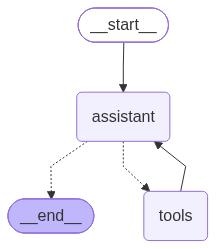

In [25]:

from graph import create_graph
from IPython.display import Image, display

# create_graph() already returns a compiled graph
graph_v1 = create_graph()

try:
    display(Image(graph_v1.get_graph().draw_mermaid_png()))
except Exception as ex:
    print("Could not render PNG:", ex)